# ЛР №2. Виртуальные сенсоры и IoT-телеметрия

Основа: `robotics-course/05-perception/class.ipynb`.

Физический ESP32/MQTT-broker не требуется: IoT-поток моделируется локально как последовательность сообщений.

**Студент:** ____________________ **Группа:** __________ **Вариант:** ____

## Критерии оценки (20 баллов)

| Часть | Содержание | Баллы |
|---|---|---:|
| 1 | Модель физического процесса и виртуальные датчики | 5 |
| 2 | Телеметрия в формате сообщений и модель канала | 5 |
| 3 | Метрики качества телеметрии (обязательный минимум) | 2 |
| 4 | Графики: исходный и принятый ряды, ошибка, актуальность | 3 |
| 5 | Исследование влияния потерь и частоты, вывод | 3 |
| 6 | Методическое задание: фрагмент урока или игра для школьников | 2 |

## Смысл работы для будущего учителя

Любой школьный проект с датчиками устроен одинаково: **датчик измеряет → данные передаются →
человек видит результат на экране**. Датчик шумит и смещается, канал теряет и задерживает
сообщения, экран показывает последнее пришедшее значение. Работа учит измерять, сколько
теряется на каждом звене, и отвечает на вопрос: **как часто устройству отправлять данные?**

Три главных вывода, которые вы проверите на своих числах:

1. **Шум частотой не лечится** — погрешность прибора не уменьшается, если опрашивать его чаще.
2. **Потери бьют по свежести, а не по точности** — пропущенное сообщение делает данные на
   экране устаревшими.
3. **«Чаще» — не всегда «лучше»** — после точки насыщения рост частоты только расходует канал
   и батарейку.

В части 6 вы превратите один из этих выводов во фрагмент урока или игру для школьников.

In [6]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt

In [4]:
# =========== Данные студента ===========
STUDENT_NAME  = "Вахрушева Варвара Сергеевна"
STUDENT_GROUP = "ИНДОР-221"
VARIANT       = 3
# ========================================

assert 1 <= VARIANT <= 25, "Вариант — целое число от 1 до 25"


def variant_params(n: int) -> dict:
    """Параметры варианта по таблице задания."""
    sensors = ["Encoder", "IMU", "Encoder+IMU", "LiDAR", "Encoder+LiDAR"]
    freqs   = [5, 10, 20, 25, 50]
    losses  = [0, 2, 5, 8, 10]
    noises  = [0.5, 1.0, 1.5, 2.0, 2.5]
    return {
        "sensor":    sensors[(n - 1) % 5],
        "freq_hz":   freqs[(n - 1) // 5],
        "noise_pct": noises[(n - 1) % 5],
        "loss_pct":  losses[(n - 1) // 5],
        "seed":      200 + n,
    }


cfg = variant_params(VARIANT)
print(f"Студент : {STUDENT_NAME}, группа {STUDENT_GROUP}")
print(f"Вариант : {VARIANT}")
for k, v in cfg.items():
    print(f"  {k:<10}: {v}")

Студент : Вахрушева Варвара Сергеевна, группа ИНДОР-221
Вариант : 3
  sensor    : Encoder+IMU
  freq_hz   : 5
  noise_pct : 1.5
  loss_pct  : 0
  seed      : 203


In [7]:
from pathlib import Path
import subprocess
import sys

REPO_URL = "https://github.com/BosenkoTM/robotics-course.git"
repo = Path("robotics-course")

if not repo.exists():
    try:
        subprocess.run(["git", "clone", "--depth", "1", "--branch", "2026",
                        REPO_URL, str(repo)], check=True, timeout=180,
                       capture_output=True)
    except Exception as err:                      # нет сети — работаем автономно
        print("Репозиторий не склонирован:", type(err).__name__)

for sub in ("04-mobile-robots", "05-perception"):
    path = (repo / sub).resolve()
    if path.exists():
        sys.path.insert(0, str(path))
        sys.path.insert(0, str(path / "lib"))

DiffDrive = None
try:
    from kinematic_models import DiffDrive          # 04-mobile-robots/lib
except Exception:
    try:
        from lib.kinematic_models import DiffDrive
    except Exception:
        DiffDrive = None

REPO_OK = DiffDrive is not None
print("Репозиторий доступен :", repo.exists())
print("DiffDrive из репозитория:", "да" if REPO_OK else "нет — используется встроенная модель")

Репозиторий доступен : True
DiffDrive из репозитория: да


In [8]:
import json
import math
import zipfile
from dataclasses import dataclass
from typing import Callable, Dict, List, Optional, Tuple

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

matplotlib.rcParams["figure.dpi"] = 110
matplotlib.rcParams["font.size"] = 9

# --- параметры эксперимента, единые для всех вариантов
DEVICE_ID  = "robot01"
SIM_TIME   = 40.0        # длительность эксперимента, с (требуется не менее 30)
DT_TRUTH   = 0.001       # шаг «физической» модели, с (1 кГц)
WHEEL_R    = 0.05        # радиус колеса, м
WHEEL_BASE = 0.20        # колея, м

# --- полные шкалы датчиков: относительно них считается уровень шума в процентах
SCALE = {
    "encoder": 1.00,     # м/с   — максимальная линейная скорость
    "imu":     2.00,     # рад/с — полная шкала гироскопа
    "lidar":   5.00,     # м     — максимальная дальность
}
UNITS = {"encoder": "м/с", "imu": "рад/с", "lidar": "м"}

ENCODER_CPR   = 1024     # импульсов на оборот вала
ENCODER_QUAD  = 4        # квадратурное декодирование: x4
IMU_BIAS0     = 0.010    # начальное смещение нуля гироскопа, рад/с
IMU_BIAS_WALK = 0.002    # случайное блуждание смещения, рад/с за секунду
LIDAR_RANGE   = SCALE["lidar"]
LIDAR_DROPOUT = 0.01     # доля недостоверных измерений дальномера

rng = np.random.default_rng(cfg["seed"])

print(f"Длительность эксперимента : {SIM_TIME} с")
print(f"Частота публикации        : {cfg['freq_hz']} Гц "
      f"(период {1000 / cfg['freq_hz']:.1f} мс)")
print(f"Ожидаемое число отсчётов  : {int(SIM_TIME * cfg['freq_hz'])}")
print(f"Датчики варианта          : {cfg['sensor']}")

Длительность эксперимента : 40.0 с
Частота публикации        : 5 Гц (период 200.0 мс)
Ожидаемое число отсчётов  : 200
Датчики варианта          : Encoder+IMU


## Задание

Используя примеры моделей из `05-perception`, сформируйте виртуальные измерения.
Каждое измерение преобразуйте в сообщение:

```json
{"device_id":"robot01","seq":1,"timestamp":0.1,"sensor":"imu","value":0.02}
```

Далее смоделируйте потери сообщений и рассчитайте метрики качества канала.

## Часть 1. Модель процесса и виртуальные датчики (5 баллов)

Сгенерируйте не менее 30 с «истинного» процесса и снимите показания датчиков вашего варианта с заданной частотой, добавив шум (процент от полной шкалы датчика) и пропуски.

## 1.1. Физический процесс

Телеметрия должна что-то измерять, поэтому сначала нужен процесс. Берём робота из
лабораторной № 1: дифференциальный привод, кинематика `DiffDrive` из `robotics-course`.
Робот едет по заданной программе — разгон, повороты в обе стороны, змейка, торможение —
чтобы в сигнале были и участки постоянной скорости, и быстрые изменения. На постоянных
участках хорошо видно шум датчика, на быстрых — потери из-за низкой частоты опроса.

Модель считается с шагом 1 мс, то есть в 20–200 раз чаще, чем публикуется телеметрия. Это
намеренно: результат такой модели мы считаем **истиной** (ground truth), с которой потом
сравниваем и измерения, и то, что дошло до получателя.

In [9]:
def control_profile(t: float) -> Tuple[float, float]:
    """Программа движения робота: (линейная скорость, угловая скорость) в момент t."""
    if t < 8.0:
        return 0.60, 0.00                    # разгон и прямолинейный участок
    if t < 14.0:
        return 0.45, 0.55                    # поворот влево
    if t < 22.0:
        return 0.70, 0.00                    # быстрый прямой участок
    if t < 28.0:
        return 0.40, -0.70                   # поворот вправо
    if t < 34.0:
        return 0.55, 0.25 * math.sin(0.9 * t)  # плавная змейка
    return 0.20, 0.00                        # торможение перед остановкой


def diff_drive_forward(pose: np.ndarray, v: float, omega: float, dt: float) -> np.ndarray:
    """Шаг кинематики дифференциального привода (метод Эйлера)."""
    x, y, th = pose
    return np.array([x + v * math.cos(th) * dt,
                     y + v * math.sin(th) * dt,
                     th + omega * dt])


robot = DiffDrive(wheel_radius=WHEEL_R, wheel_base=WHEEL_BASE) if REPO_OK else None
step = (lambda p, v, w, dt: robot.forward(p, v, w, dt)) if REPO_OK else diff_drive_forward

n_truth = int(SIM_TIME / DT_TRUTH) + 1
pose = np.array([0.5, 0.5, 0.0])
rows = []
for k in range(n_truth):
    t = k * DT_TRUTH
    v, omega = control_profile(t)
    rows.append({"t": t, "x": pose[0], "y": pose[1], "theta": pose[2],
                 "v": v, "omega": omega,
                 "w_right": (v + omega * WHEEL_BASE / 2) / WHEEL_R,
                 "w_left":  (v - omega * WHEEL_BASE / 2) / WHEEL_R})
    pose = step(pose, v, omega, DT_TRUTH)

truth = pd.DataFrame(rows)

print(f"Эталонная траектория: {len(truth)} точек с шагом {DT_TRUTH * 1000:.0f} мс")
print(f"Пройденный путь     : {float(truth['v'].sum() * DT_TRUTH):.2f} м")
print(f"Диапазон v          : {truth['v'].min():.2f} … {truth['v'].max():.2f} м/с")
print(f"Диапазон omega      : {truth['omega'].min():.2f} … {truth['omega'].max():.2f} рад/с")
truth.head(3)

Эталонная траектория: 40001 точек с шагом 1 мс
Пройденный путь     : 20.00 м
Диапазон v          : 0.20 … 0.70 м/с
Диапазон omega      : -0.70 … 0.55 рад/с


,t,x,y,theta,v,omega,w_right,w_left
0,0.000,0.5000,0.5,0.0,0.6,0.0,12.0,12.0
1,0.001,0.5006,0.5,0.0,0.6,0.0,12.0,12.0
2,0.002,0.5012,0.5,0.0,0.6,0.0,12.0,12.0


## 1.2. Модели виртуальных датчиков

Три датчика, каждый со своим характерным искажением. Структура моделей повторяет каталог
`05-perception` репозитория: отдельная функция или класс на датчик, на входе истинное
значение, на выходе — измеренное.

In [10]:
OBSTACLES = [(4.0, 3.0, 0.60), (7.5, 6.0, 0.80), (2.0, 6.5, 0.50)]


def ray_distance(pose: np.ndarray, obstacles: list, max_range: float) -> float:
    """Дальность по лучу вдоль курса робота до ближайшего препятствия."""
    ox, oy, th = pose
    dx, dy = math.cos(th), math.sin(th)
    best = max_range
    for cx, cy, r in obstacles:
        fx, fy = ox - cx, oy - cy
        b = 2.0 * (fx * dx + fy * dy)
        c = fx * fx + fy * fy - r * r
        disc = b * b - 4.0 * c
        if disc < 0.0:
            continue
        sq = math.sqrt(disc)
        for t in ((-b - sq) / 2.0, (-b + sq) / 2.0):
            if 0.0 <= t < best:
                best = t
    return float(best)


def encoder_truth(row: pd.Series) -> float:
    """Истинная линейная скорость, восстановленная по угловым скоростям колёс, м/с."""
    return WHEEL_R * (row["w_right"] + row["w_left"]) / 2.0


def encoder_measure(value: float, sigma: float, generator: np.random.Generator) -> float:
    """Модель энкодера: шум + квантование по разрешению датчика."""
    resolution = 2 * math.pi * WHEEL_R / (ENCODER_CPR * ENCODER_QUAD)   # м на импульс
    noisy = value + generator.normal(0.0, sigma)
    return float(round(noisy / resolution) * resolution)                # квантование


class ImuModel:
    """Гироскоп: белый шум измерения плюс дрейф нуля (случайное блуждание)."""

    def __init__(self, sigma: float, generator: np.random.Generator):
        self.sigma = sigma
        self.rng = generator
        self.bias = IMU_BIAS0

    def measure(self, value: float, dt: float) -> float:
        self.bias += self.rng.normal(0.0, IMU_BIAS_WALK * math.sqrt(max(dt, 1e-9)))
        return float(value + self.bias + self.rng.normal(0.0, self.sigma))


def lidar_measure(value: float, sigma: float, generator: np.random.Generator) -> float:
    """Дальномер: шум измерения и редкие недостоверные отсчёты (dropout)."""
    if generator.random() < LIDAR_DROPOUT:
        return float("nan")
    return float(np.clip(value + generator.normal(0.0, sigma), 0.0, LIDAR_RANGE))


def sensors_of(variant_sensor: str) -> List[str]:
    """Список потоков телеметрии по названию сенсора варианта."""
    return [s.strip().lower() for s in variant_sensor.split("+")]


STREAMS = sensors_of(cfg["sensor"])
SIGMA = {s: cfg["noise_pct"] / 100.0 * SCALE[s] for s in STREAMS}

print("Потоки телеметрии варианта:", STREAMS)
for s in STREAMS:
    print(f"  {s:<8} полная шкала {SCALE[s]} {UNITS[s]:<6} "
          f"-> сигма шума {SIGMA[s]:.4f} {UNITS[s]}")
print(f"\nРазрешение энкодера: "
      f"{2 * math.pi * WHEEL_R / (ENCODER_CPR * ENCODER_QUAD) * 1000:.4f} мм на импульс")
_p = np.array([0.5, 0.5, 0.0])
print(f"Проверка дальномера: в пустом поле {ray_distance(_p, [], LIDAR_RANGE):.2f} м, "
      f"на препятствие в 2 м {ray_distance(np.array([2.0, 3.0, 0.0]), [(4.0, 3.0, 0.6)], LIDAR_RANGE):.2f} м")

Потоки телеметрии варианта: ['encoder', 'imu']
  encoder  полная шкала 1.0 м/с    -> сигма шума 0.0150 м/с
  imu      полная шкала 2.0 рад/с  -> сигма шума 0.0300 рад/с

Разрешение энкодера: 0.0767 мм на импульс
Проверка дальномера: в пустом поле 5.00 м, на препятствие в 2 м 1.40 м


## 1.3. Снятие показаний с частотой варианта

**Разбор ячейки.** Опрос датчиков — это **прореживание** эталонного ряда: из 40 000 точек
модели берутся только те, что попадают на сетку с периодом $1/f$. Индекс вычисляется как
`t / DT_TRUTH`, то есть выборка идёт без интерполяции — так же, как реальный микроконтроллер
читает регистр датчика в момент опроса.

Функция намеренно сделана самодостаточной: она принимает конфигурацию варианта и генератор,
а список потоков и сигмы вычисляет внутри. Благодаря этому её можно вызывать с изменёнными
параметрами в части 5, не трогая глобальное состояние.

In [11]:
def sample_measurements(truth: pd.DataFrame, variant_cfg: dict,
                        generator: np.random.Generator) -> pd.DataFrame:
    """Снять показания датчиков с частотой варианта.

    Args:
        truth: эталонная траектория с шагом ``DT_TRUTH``.
        variant_cfg: конфигурация варианта (``sensor``, ``freq_hz``, ``noise_pct``).
        generator: генератор случайных чисел (задаёт воспроизводимость).

    Returns:
        DataFrame с колонками ``t``, ``sensor``, ``truth``, ``measured``, ``unit``.
    """
    streams = sensors_of(variant_cfg["sensor"])
    sigma = {s: variant_cfg["noise_pct"] / 100.0 * SCALE[s] for s in streams}
    period = 1.0 / variant_cfg["freq_hz"]
    times = np.arange(0.0, SIM_TIME, period)
    index = (times / DT_TRUTH).astype(int)
    imu = ImuModel(sigma.get("imu", 0.0), generator)

    records: List[dict] = []
    for t, idx in zip(times, index):
        row = truth.iloc[idx]
        pose = np.array([row["x"], row["y"], row["theta"]])
        for stream in streams:
            if stream == "encoder":
                true_value = encoder_truth(row)
                measured = encoder_measure(true_value, sigma["encoder"], generator)
            elif stream == "imu":
                true_value = float(row["omega"])
                measured = imu.measure(true_value, period)
            else:
                true_value = ray_distance(pose, OBSTACLES, LIDAR_RANGE)
                measured = lidar_measure(true_value, sigma["lidar"], generator)
            records.append({"t": float(t), "sensor": stream,
                            "truth": float(true_value), "measured": measured,
                            "unit": UNITS[stream]})
    return pd.DataFrame(records)


meas = sample_measurements(truth, cfg, rng)

print(f"Снято отсчётов: {len(meas)} "
      f"({len(STREAMS)} поток(а) x {len(meas) // len(STREAMS)} отсчётов)")
print(f"Недостоверных измерений (NaN): {int(meas['measured'].isna().sum())}\n")
summary = (meas.dropna(subset=["measured"])
           .assign(err=lambda d: d["measured"] - d["truth"])
           .groupby("sensor")
           .agg(n=("err", "size"), bias=("err", "mean"),
                rmse=("err", lambda e: float(np.sqrt(np.mean(e ** 2)))),
                max_abs=("err", lambda e: float(np.max(np.abs(e)))))
           .round(5))
print(summary.to_string())
meas.head(4)

Снято отсчётов: 400 (2 поток(а) x 200 отсчётов)
Недостоверных измерений (NaN): 0

           n     bias     rmse  max_abs
sensor                                 
encoder  200  0.00056  0.01433  0.04907
imu      200  0.01777  0.03529  0.09935


,t,sensor,truth,measured,unit
0,0.0,encoder,0.6,0.592040,м/с
1,0.0,imu,0.0,0.037968,рад/с
2,0.2,encoder,0.6,0.624484,м/с
3,0.2,imu,0.0,0.076433,рад/с


## Часть 2. Телеметрия и модель канала (5 баллов)

## 2.1. Формирование сообщений

Преобразуйте измерения в сообщения `device_id / seq / timestamp / sensor / value` и смоделируйте публикацию и приём: потери по варианту, задержку доставки.

In [13]:
def build_messages(meas: pd.DataFrame, device_id: str = DEVICE_ID) -> List[dict]:
    """Преобразовать измерения в сообщения телеметрии.

    Формат сообщения соответствует заданию:
    ``{"device_id", "seq", "timestamp", "sensor", "value"}``.
    """
    messages: List[dict] = []
    for seq, row in enumerate(meas.sort_values("t").itertuples(index=False), start=1):
        value = None if (isinstance(row.measured, float) and math.isnan(row.measured)) \
            else round(float(row.measured), 6)
        messages.append({"device_id": device_id,
                         "seq": seq,
                         "timestamp": round(float(row.t), 4),
                         "sensor": row.sensor,
                         "value": value})
    return messages


messages = build_messages(meas)
payload_bytes = [len(json.dumps(m, ensure_ascii=False).encode("utf-8")) for m in messages]

print("Пример сообщения:")
print(json.dumps(messages[0], ensure_ascii=False))
print(json.dumps(messages[1], ensure_ascii=False))
print(f"\nВсего сообщений        : {len(messages)}")
print(f"Средний размер payload : {np.mean(payload_bytes):.1f} байт")
print(f"Полезная нагрузка канала: {np.mean(payload_bytes) * len(messages) / SIM_TIME:.0f} байт/с "
      f"({np.mean(payload_bytes) * len(messages) / SIM_TIME * 8 / 1000:.2f} кбит/с)")

Пример сообщения:
{"device_id": "robot01", "seq": 1, "timestamp": 0.0, "sensor": "imu", "value": 0.037968}
{"device_id": "robot01", "seq": 2, "timestamp": 0.0, "sensor": "encoder", "value": 0.59204}

Всего сообщений        : 400
Средний размер payload : 92.5 байт
Полезная нагрузка канала: 925 байт/с (7.40 кбит/с)


## 2.2. Публикация и приём

Канал моделируется функцией: на входе список отправленных сообщений, на выходе — то, что
дошло до потребителя, с временем приёма. Никакой сети здесь нет, и это принципиально:
случайность полностью управляется зерном генератора, поэтому эксперимент воспроизводим.

**Разбор ячейки.** Параметры канала вынесены в `dataclass` — это не украшение, а способ
сделать эксперимент управляемым: в части 5 достаточно передать другой `ChannelConfig`, не
переписывая функцию передачи.

Логика `transmit`: для каждого сообщения бросается «монета» с вероятностью потери; при потере
запускается серия длиной `burst_len` (по умолчанию 1 — потери независимы). Доставленному
сообщению приписывается задержка: базовая плюс экспоненциальная добавка. Приёмник сортирует
принятое по времени прибытия — так моделируется возможное переупорядочивание.

In [14]:
@dataclass
class ChannelConfig:
    """Параметры виртуального канала связи."""
    loss_pct: float = 0.0        # вероятность потери отдельного сообщения, %
    base_delay_s: float = 0.005  # базовая задержка доставки, с
    jitter_s: float = 0.004      # разброс задержки (экспоненциальный хвост), с
    burst_len: int = 1           # средняя длина серии потерь (1 = потери независимы)


def transmit(messages: List[dict], channel: ChannelConfig,
             generator: np.random.Generator) -> pd.DataFrame:
    """Промоделировать публикацию и приём сообщений.

    Сообщение теряется с вероятностью ``loss_pct``; при ``burst_len > 1`` потери
    группируются в серии. Каждому доставленному сообщению приписывается время приёма
    с задержкой и джиттером. Приёмник сортирует сообщения по времени прибытия.

    Returns:
        DataFrame принятых сообщений с колонками
        ``seq, sensor, timestamp, value, t_rx, delay``.
    """
    p_loss = channel.loss_pct / 100.0
    received: List[dict] = []
    burst_left = 0

    for message in messages:
        if burst_left > 0:                       # продолжается серия потерь
            burst_left -= 1
            continue
        if generator.random() < p_loss:
            burst_left = max(0, channel.burst_len - 1)
            continue
        delay = channel.base_delay_s + generator.exponential(channel.jitter_s)
        received.append({**message, "t_rx": message["timestamp"] + delay,
                         "delay": delay})

    frame = pd.DataFrame(received)
    return frame.sort_values("t_rx").reset_index(drop=True) if len(frame) else frame


channel = ChannelConfig(loss_pct=cfg["loss_pct"])
rx = transmit(messages, channel, rng)

lost_seq = sorted(set(m["seq"] for m in messages) - set(rx["seq"]))
print(f"Отправлено : {len(messages)}")
print(f"Принято    : {len(rx)}")
print(f"Потеряно   : {len(lost_seq)} "
      f"({100 * len(lost_seq) / len(messages):.2f} %, "
      f"задано в варианте {cfg['loss_pct']} %)")
print(f"Задержка   : медиана {rx['delay'].median() * 1000:.1f} мс, "
      f"максимум {rx['delay'].max() * 1000:.1f} мс")
print(f"Первые потерянные seq: {lost_seq[:10]}")
rx.head(3)

Отправлено : 400
Принято    : 400
Потеряно   : 0 (0.00 %, задано в варианте 0 %)
Задержка   : медиана 7.9 мс, максимум 41.0 мс
Первые потерянные seq: []


,device_id,seq,timestamp,sensor,value,t_rx,delay
0,robot01,2,0.0,encoder,0.592040,0.008330,0.008330
1,robot01,1,0.0,imu,0.037968,0.011981,0.011981
2,robot01,3,0.2,imu,0.076433,0.205215,0.005215


## Часть 3. Метрики качества (2 балла)

Обязательный минимум — по 0,5 балла за каждую метрику:

| Метрика | Что показывает |
|---|---|
| фактическая частота приёма, Гц | сколько сообщений в секунду реально дошло |
| фактическая доля потерь, % | сравнить с заданной; объяснить расхождение |
| ошибка датчика (RMSE измерения) | насколько точен сам прибор |
| ошибка у потребителя (RMSE восстановленного сигнала) | насколько точно то, что видно на экране |

Серии потерь, задержка, разрывы и возраст данных — по желанию (расширенный уровень).

In [15]:
def zoh_reconstruct(rx_stream: pd.DataFrame, grid: np.ndarray) -> np.ndarray:
    """Восстановить сигнал на равномерной сетке экстраполяцией «нуль-порядка».

    Потребитель телеметрии видит только принятые сообщения и до прихода следующего
    держит последнее известное значение (zero-order hold).
    """
    values = rx_stream["value"].to_numpy(dtype=float)
    stamps = rx_stream["timestamp"].to_numpy(dtype=float)
    valid = ~np.isnan(values)
    values, stamps = values[valid], stamps[valid]
    if len(stamps) == 0:
        return np.full_like(grid, np.nan, dtype=float)
    idx = np.searchsorted(stamps, grid, side="right") - 1
    return np.where(idx >= 0, values[np.clip(idx, 0, None)], np.nan)


def age_of_information(rx_stream: pd.DataFrame, grid: np.ndarray) -> np.ndarray:
    """Возраст информации: время с момента формирования последнего принятого пакета."""
    stamps = np.sort(rx_stream["timestamp"].to_numpy(dtype=float))
    if len(stamps) == 0:
        return np.full_like(grid, np.nan, dtype=float)
    idx = np.searchsorted(stamps, grid, side="right") - 1
    return np.where(idx >= 0, grid - stamps[np.clip(idx, 0, None)], np.nan)


def channel_metrics(messages: List[dict], rx: pd.DataFrame, meas: pd.DataFrame,
                    variant_cfg: dict) -> dict:
    """Метрики качества виртуального IoT-канала и восстановления сигнала."""
    streams = sensors_of(variant_cfg["sensor"])
    n_sent = len(messages)
    seq_sent = np.array([m["seq"] for m in messages])
    seq_rx = np.sort(rx["seq"].to_numpy()) if len(rx) else np.array([], dtype=int)
    lost = np.setdiff1d(seq_sent, seq_rx)
    gaps = np.diff(seq_rx)

    result = {
        "messages_sent":      n_sent,
        "messages_received":  len(rx),
        "loss_pct_actual":    round(100.0 * len(lost) / n_sent, 3),
        "pdr_pct":            round(100.0 * len(rx) / n_sent, 3),
        "rate_nominal_hz":    variant_cfg["freq_hz"] * len(streams),
        "rate_actual_hz":     round(len(rx) / SIM_TIME, 3),
        "longest_loss_burst": int(gaps.max() - 1) if len(gaps) else 0,
        "delay_median_ms":    round(float(rx["delay"].median()) * 1000, 2) if len(rx) else None,
        "jitter_ms":          round(float(rx["delay"].std()) * 1000, 2) if len(rx) else None,
    }

    grid = np.arange(0.0, SIM_TIME, 0.01)
    for stream in streams:
        src = meas[meas["sensor"] == stream].sort_values("t")
        err = (src["measured"] - src["truth"]).dropna().to_numpy()
        truth_grid = np.interp(grid, src["t"], src["truth"])

        rx_s = rx[rx["sensor"] == stream].sort_values("timestamp") if len(rx) else rx
        recon = zoh_reconstruct(rx_s, grid) if len(rx_s) else np.full(len(grid), np.nan)
        ok = ~np.isnan(recon)
        stamps = rx_s["timestamp"].to_numpy() if len(rx_s) else np.array([])
        gap_s = np.diff(np.r_[0.0, stamps, SIM_TIME])
        aoi = age_of_information(rx_s, grid) if len(rx_s) else np.full(len(grid), np.nan)

        result[f"{stream}_sensor_rmse"] = round(float(np.sqrt(np.mean(err ** 2))), 5)
        result[f"{stream}_sensor_bias"] = round(float(np.mean(err)), 5)
        result[f"{stream}_recon_rmse"] = round(float(np.sqrt(np.mean(
            (recon[ok] - truth_grid[ok]) ** 2))), 5) if ok.any() else None
        result[f"{stream}_max_gap_s"] = round(float(gap_s.max()), 3)
        result[f"{stream}_aoi_mean_s"] = round(float(np.nanmean(aoi)), 4)
        result[f"{stream}_aoi_max_s"] = round(float(np.nanmax(aoi)), 4)
    return result


metrics = channel_metrics(messages, rx, meas, cfg)
print(pd.Series(metrics, dtype=object).to_string())

messages_sent              400
messages_received          400
loss_pct_actual            0.0
pdr_pct                  100.0
rate_nominal_hz             10
rate_actual_hz            10.0
longest_loss_burst           0
delay_median_ms            7.9
jitter_ms                 4.22
encoder_sensor_rmse    0.01433
encoder_sensor_bias    0.00056
encoder_recon_rmse     0.02656
encoder_max_gap_s          0.2
encoder_aoi_mean_s       0.095
encoder_aoi_max_s         0.19
imu_sensor_rmse        0.03529
imu_sensor_bias        0.01777
imu_recon_rmse         0.06223
imu_max_gap_s              0.2
imu_aoi_mean_s           0.095
imu_aoi_max_s             0.19


## Часть 4. Графики (3 балла)

Истинный, измеренный и принятый ряды; ошибка датчика; при желании — интервалы прибытия и возраст данных. Подпишите оси и единицы измерения.

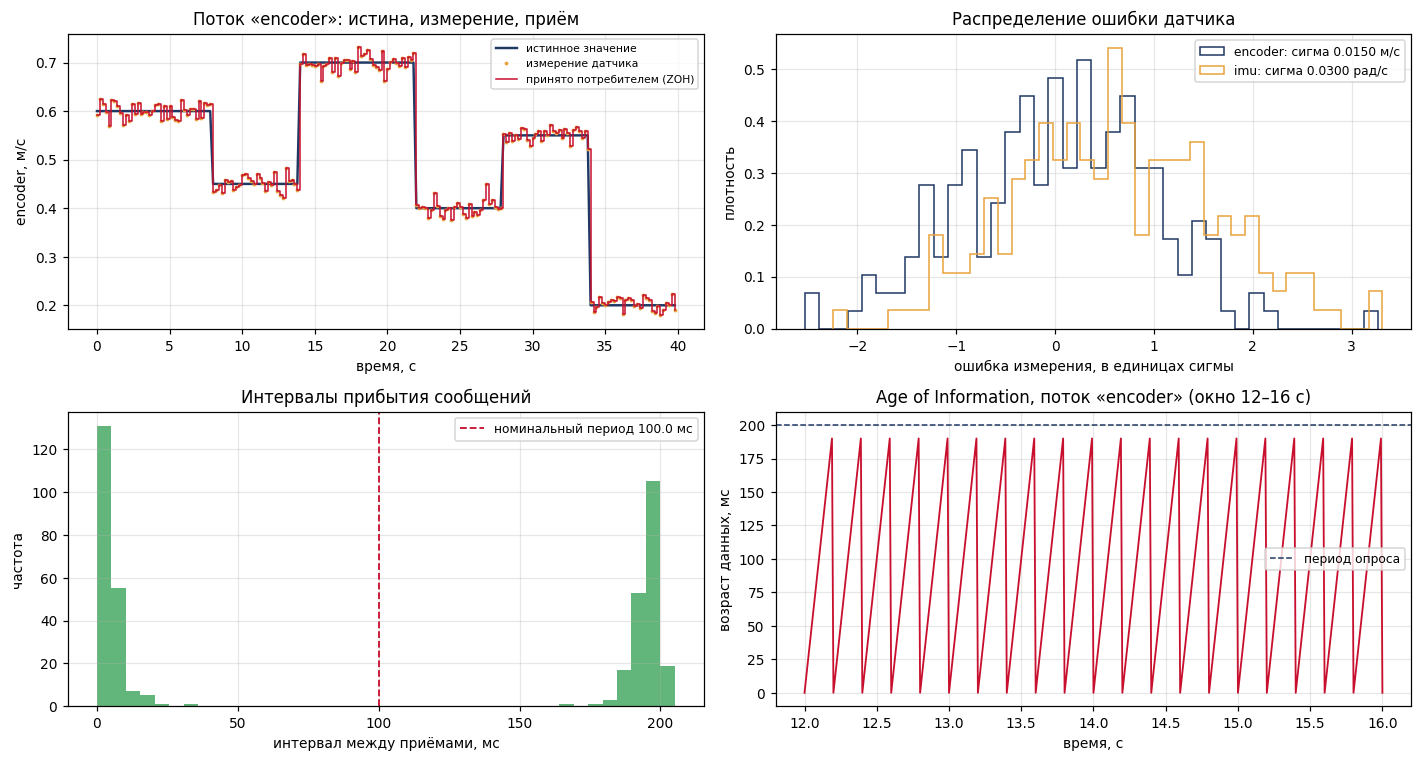

In [16]:
grid = np.arange(0.0, SIM_TIME, 0.01)
fig, axes = plt.subplots(2, 2, figsize=(13, 7))

# --- 1. исходный, измеренный и принятый ряды по первому потоку
stream = STREAMS[0]
src = meas[meas["sensor"] == stream]
rx_s = rx[rx["sensor"] == stream].sort_values("timestamp")
ax = axes[0, 0]
ax.plot(src["t"], src["truth"], lw=1.6, color="#1F3864", label="истинное значение", zorder=2)
ax.plot(src["t"], src["measured"], ".", ms=3, color="#E8A33D",
        label="измерение датчика", zorder=3)
ax.step(rx_s["timestamp"], rx_s["value"], where="post", lw=1.0, color="#C8102E",
        label="принято потребителем (ZOH)", zorder=4)
ax.set_xlabel("время, с"); ax.set_ylabel(f"{stream}, {UNITS[stream]}")
ax.set_title(f"Поток «{stream}»: истина, измерение, приём")
ax.grid(alpha=.3); ax.legend(fontsize=7)

# --- 2. ошибка измерения
ax = axes[0, 1]
for s, color in zip(STREAMS, ["#1F3864", "#E8A33D", "#2E9E4F"]):
    d = meas[meas["sensor"] == s].dropna(subset=["measured"])
    err = (d["measured"] - d["truth"]) / SIGMA[s]
    ax.hist(err, bins=40, histtype="step", lw=1.6, density=True, color=color,
            label=f"{s}: сигма {SIGMA[s]:.4f} {UNITS[s]}")
ax.set_xlabel("ошибка измерения, в единицах сигмы"); ax.set_ylabel("плотность")
ax.set_title("Распределение ошибки датчика")
ax.grid(alpha=.3); ax.legend(fontsize=8)

# --- 3. интервалы между принятыми сообщениями
ax = axes[1, 0]
inter = np.diff(rx["t_rx"].to_numpy()) * 1000
ax.hist(inter, bins=40, color="#2E9E4F", alpha=.75)
nominal = 1000.0 / (cfg["freq_hz"] * len(STREAMS))
ax.axvline(nominal, color="#C8102E", ls="--", lw=1.2,
           label=f"номинальный период {nominal:.1f} мс")
ax.set_xlabel("интервал между приёмами, мс"); ax.set_ylabel("частота")
ax.set_title("Интервалы прибытия сообщений")
ax.grid(alpha=.3); ax.legend(fontsize=8)

# --- 4. возраст информации
ax = axes[1, 1]
window = (grid >= 12.0) & (grid <= 16.0)          # окно 4 с: иначе пила не читается
aoi = age_of_information(rx_s, grid)
ax.plot(grid[window], aoi[window] * 1000, lw=1.2, color="#C8102E")
ax.axhline(1000.0 / cfg["freq_hz"], color="#1F3864", ls="--", lw=1.0,
           label="период опроса")
ax.set_xlabel("время, с"); ax.set_ylabel("возраст данных, мс")
ax.set_title(f"Age of Information, поток «{stream}» (окно 12–16 с)")
ax.grid(alpha=.3); ax.legend(fontsize=8)

plt.tight_layout(); plt.show()

## 4.1. Уточнение: возраст информации по определению

В теоретической части AoI определён как $\Delta(t) = t - u(t)$, где $u(t)$ — время
**измерения** самого свежего сообщения, **уже полученного** к моменту $t$. Функция
`age_of_information` в части 3 упрощает расчёт двумя способами: считает сообщение доступным
сразу в момент измерения (без задержки доставки) и оценивает возраст на сетке 10 мс. Ячейка
ниже считает AoI строго по определению — с временем приёма `t_rx` и на сетке 0,5 мс. Код
основной части не меняется: это дополнительная проверка.

In [17]:
# ============================================================================
#  Дополнительная ячейка: возраст информации по определению
#  AoI(t) = t − u(t), где u(t) — время ИЗМЕРЕНИЯ самого свежего сообщения,
#  которое к моменту t уже ПРИШЛО потребителю. Функция age_of_information выше
#  упрощает: считает сообщение доступным в момент измерения (без задержки
#  доставки) и оценивает возраст на сетке 10 мс. Здесь — точная версия.
# ============================================================================
def aoi_delivered(rx_stream: pd.DataFrame, step: float = 0.0005) -> Tuple[float, float]:
    """Средний и максимальный AoI с учётом времени приёма, сетка 0,5 мс."""
    t_grid = np.arange(0.0, SIM_TIME, step)
    order = np.argsort(rx_stream["t_rx"].to_numpy())
    arrived = rx_stream["t_rx"].to_numpy()[order]
    # самое свежее измерение среди пришедших (с учётом переупорядочивания)
    freshest = np.maximum.accumulate(rx_stream["timestamp"].to_numpy()[order])
    idx = np.searchsorted(arrived, t_grid, side="right") - 1
    age = np.where(idx >= 0, t_grid - freshest[np.clip(idx, 0, None)], np.nan)
    return float(np.nanmean(age)), float(np.nanmax(age))


print(f"{'поток':<8} {'AoI упрощённый, мс':>22} {'AoI по определению, мс':>26}")
for _s in STREAMS:
    _rx_s = rx[rx["sensor"] == _s]
    _mean, _max = aoi_delivered(_rx_s)
    print(f"{_s:<8} {metrics[f'{_s}_aoi_mean_s'] * 1000:>9.1f} / {metrics[f'{_s}_aoi_max_s'] * 1000:<9.1f}"
          f" {_mean * 1000:>12.1f} / {_max * 1000:<9.1f}")
print("\nформат: средний / максимальный; теоретический минимум среднего без потерь "
      f"= половина периода + средняя задержка ≈ {500 / cfg['freq_hz']:.0f} + "
      f"{rx['delay'].mean() * 1000:.1f} мс")

поток        AoI упрощённый, мс     AoI по определению, мс
encoder       95.0 / 190.0            109.1 / 228.5    
imu           95.0 / 190.0            109.1 / 240.5    

формат: средний / максимальный; теоретический минимум среднего без потерь = половина периода + средняя задержка ≈ 100 + 9.1 мс


## Часть 5. Исследование (3 балла)

Измените по одному параметру (доля потерь, частота публикации), остальные оставьте как в варианте. Постройте таблицу и график зависимости метрик от параметра.


## 5.1. Влияние потерь пакетов

Однофакторный эксперимент: меняется только доля потерь, все остальные параметры и зерно
генератора фиксированы. Диапазон намеренно расширен далеко за пределы варианта (до 50 %),
чтобы эффект стал видимым.

In [18]:
def run_pipeline(variant_cfg: dict, loss_pct: float = None,
                 freq_hz: float = None) -> dict:
    """Полный прогон конвейера «датчик -> сообщения -> канал -> метрики».

    Меняется ровно один параметр, остальные берутся из конфигурации варианта:
    это однофакторный эксперимент.
    """
    local = dict(variant_cfg)
    if loss_pct is not None:
        local["loss_pct"] = loss_pct
    if freq_hz is not None:
        local["freq_hz"] = freq_hz

    generator = np.random.default_rng(local["seed"])
    local_meas = sample_measurements(truth, local, generator)
    local_messages = build_messages(local_meas)
    local_rx = transmit(local_messages, ChannelConfig(loss_pct=local["loss_pct"]), generator)
    result = channel_metrics(local_messages, local_rx, local_meas, local)
    return {"freq_hz": local["freq_hz"], "loss_pct": local["loss_pct"], **result}


first = STREAMS[0]
loss_sweep = pd.DataFrame([run_pipeline(cfg, loss_pct=p)
                           for p in [0, 2, 5, 10, 20, 30, 50]])[
    ["loss_pct", "messages_received", "loss_pct_actual", "rate_actual_hz",
     "longest_loss_burst", f"{first}_recon_rmse", f"{first}_max_gap_s",
     f"{first}_aoi_mean_s", f"{first}_aoi_max_s"]]

print(f"Влияние потерь пакетов (частота {cfg['freq_hz']} Гц, поток «{first}»)\n")
print(loss_sweep.to_string(index=False))

Влияние потерь пакетов (частота 5 Гц, поток «encoder»)

 loss_pct  messages_received  loss_pct_actual  rate_actual_hz  longest_loss_burst  encoder_recon_rmse  encoder_max_gap_s  encoder_aoi_mean_s  encoder_aoi_max_s
        0                400             0.00          10.000                   0             0.02656                0.2               0.095               0.19
        2                394             1.50           9.850                   1             0.02656                0.6               0.098               0.59
        5                377             5.75           9.425                   2             0.02644                0.4               0.107               0.39
       10                360            10.00           9.000                   4             0.02622                0.6               0.121               0.59
       20                324            19.00           8.100                   4             0.03678                0.6               0.145    

## 5.1а. Один прогон — не доказательство

Та же зависимость от потерь, но на 30 разных зёрнах генератора: параметры не меняются,
меняется только случайная реализация шума и потерь. Так проверяют, какие особенности кривой
— закономерность, а какие — случайность.

In [ ]:
# ============================================================================
#  Дополнительная ячейка: один прогон — не доказательство
#  Тот же однофакторный эксперимент, но на 30 разных зёрнах генератора.
#  Меняется только случайная реализация шума и потерь, параметры те же.
# ============================================================================
_rows = []
for _p in [0, 2, 5, 10, 20, 30, 50]:
    _runs = [run_pipeline(dict(cfg, seed=_s), loss_pct=_p) for _s in range(300, 330)]
    _rmse = np.array([r[f"{first}_recon_rmse"] for r in _runs])
    _rows.append({"loss_pct": _p,
                  "recon_rmse_mean": round(float(_rmse.mean()), 5),
                  "recon_rmse_sd": round(float(_rmse.std()), 5),
                  "max_gap_mean_s": round(float(np.mean([r[f"{first}_max_gap_s"] for r in _runs])), 3),
                  "aoi_mean_s": round(float(np.mean([r[f"{first}_aoi_mean_s"] for r in _runs])), 4)})
seed_sweep = pd.DataFrame(_rows)
print(f"Влияние потерь, среднее по 30 прогонам (поток «{first}»)\n")
print(seed_sweep.to_string(index=False))

Влияние потерь, среднее по 30 прогонам (поток «encoder»)

 loss_pct  recon_rmse_mean  recon_rmse_sd  max_gap_mean_s  aoi_mean_s
        0          0.01787        0.00030           0.050      0.0200
        2          0.01800        0.00063           0.113      0.0210
        5          0.01809        0.00095           0.142      0.0226
       10          0.01909        0.00178           0.177      0.0256
       20          0.02009        0.00305           0.257      0.0323
       30          0.02169        0.00360           0.322      0.0420
       50          0.02639        0.00461           0.510      0.0711


## 5.1б. Проверка гипотезы о сериях потерь

В выводе работы (п. 4) утверждается: опасны не потери сами по себе, а **длинные серии**
подряд потерянных пакетов. В основном эксперименте потери независимые (`burst_len = 1`),
поэтому гипотеза там не проверялась. Проверим её: общая доля потерь одинакова — около 5 %,
а длина серии растёт от 1 до 5. Вероятность начала серии подобрана так, чтобы итоговая доля
потерь осталась прежней.

In [19]:
# ============================================================================
#  Дополнительная ячейка: проверка гипотезы «опасны не потери, а их серии»
#  Доля потерь одинакова (~5 %), различается только длина серии burst_len.
#  Вероятность начала серии подобрана так, чтобы общая доля потерь сохранилась.
# ============================================================================
_rows = []
for _bl in [1, 3, 5]:
    _p_start = 5.0 / (_bl - 0.05 * (_bl - 1))      # итоговая доля потерь ≈ 5 %
    _res = []
    for _s in range(300, 330):
        _gen = np.random.default_rng(_s)
        _cfg = dict(cfg, seed=_s)
        _meas = sample_measurements(truth, _cfg, _gen)
        _msgs = build_messages(_meas)
        _rx = transmit(_msgs, ChannelConfig(loss_pct=_p_start, burst_len=_bl), _gen)
        _res.append(channel_metrics(_msgs, _rx, _meas, _cfg))
    _rows.append({"burst_len": _bl,
                  "loss_actual_pct": round(float(np.mean([r["loss_pct_actual"] for r in _res])), 2),
                  f"{first}_recon_rmse": round(float(np.mean([r[f"{first}_recon_rmse"] for r in _res])), 5),
                  f"{first}_max_gap_s": round(float(np.mean([r[f"{first}_max_gap_s"] for r in _res])), 3),
                  f"{first}_aoi_max_s": round(float(np.mean([r[f"{first}_aoi_max_s"] for r in _res])), 3)})
burst_test = pd.DataFrame(_rows)
print("Одинаковая доля потерь, разная длина серий (среднее по 30 прогонам)\n")
print(burst_test.to_string(index=False))

Одинаковая доля потерь, разная длина серий (среднее по 30 прогонам)

 burst_len  loss_actual_pct  encoder_recon_rmse  encoder_max_gap_s  encoder_aoi_max_s
         1             4.54             0.02856              0.467              0.457
         3             5.11             0.02848              0.640              0.630
         5             5.17             0.02881              0.760              0.750


## 5.2. Влияние частоты публикации

In [23]:
freq_rows = [run_pipeline(cfg, freq_hz=f) for f in [5, 10, 20, 25, 50]]
freq_sweep = pd.DataFrame(freq_rows)[
    ["freq_hz", "messages_sent", "messages_received", "rate_actual_hz",
     f"{first}_sensor_rmse", f"{first}_recon_rmse",
     f"{first}_max_gap_s", f"{first}_aoi_mean_s"]]
freq_sweep["payload_bps"] = (freq_sweep["messages_received"] *
                             np.mean(payload_bytes) * 8 / SIM_TIME).round(0)

print(f"Влияние частоты публикации (потери {cfg['loss_pct']} %, поток «{first}»)\n")
print(freq_sweep.to_string(index=False))

Влияние частоты публикации (потери 0 %, поток «encoder»)

 freq_hz  messages_sent  messages_received  rate_actual_hz  encoder_sensor_rmse  encoder_recon_rmse  encoder_max_gap_s  encoder_aoi_mean_s  payload_bps
       5            400                400            10.0              0.01433             0.02656               0.20               0.095       7402.0
      10            800                800            20.0              0.01515             0.02117               0.10               0.045      14804.0
      20           1600               1600            40.0              0.01525             0.01813               0.05               0.020      29609.0
      25           2000               2000            50.0              0.01508             0.01721               0.04               0.015      37011.0
      50           4000               4000           100.0              0.01487             0.01554               0.02               0.005      74022.0


## 5.3. Графики исследования

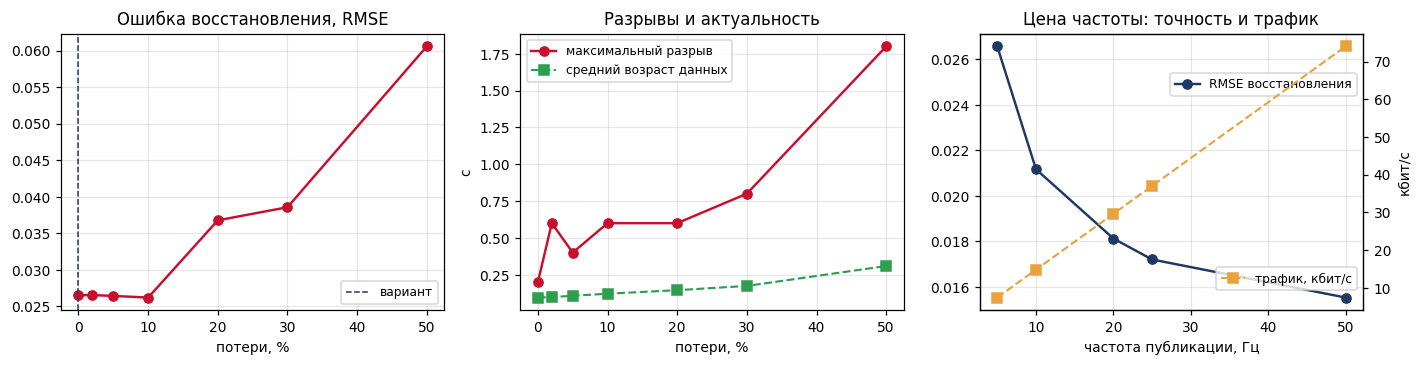

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))

axes[0].plot(loss_sweep["loss_pct"], loss_sweep[f"{first}_recon_rmse"],
             "o-", color="#C8102E", lw=1.6)
axes[0].axvline(cfg["loss_pct"], color="#1F3864", ls="--", lw=1.0, label="вариант")
axes[0].set_xlabel("потери, %"); axes[0].set_title("Ошибка восстановления, RMSE")
axes[0].legend(fontsize=8)

axes[1].plot(loss_sweep["loss_pct"], loss_sweep[f"{first}_max_gap_s"],
             "o-", color="#C8102E", lw=1.6, label="максимальный разрыв")
axes[1].plot(loss_sweep["loss_pct"], loss_sweep[f"{first}_aoi_mean_s"],
             "s--", color="#2E9E4F", lw=1.4, label="средний возраст данных")
axes[1].set_xlabel("потери, %"); axes[1].set_ylabel("с")
axes[1].set_title("Разрывы и актуальность"); axes[1].legend(fontsize=8)

axes[2].plot(freq_sweep["freq_hz"], freq_sweep[f"{first}_recon_rmse"],
             "o-", color="#1F3864", lw=1.6, label="RMSE восстановления")
ax2 = axes[2].twinx()
ax2.plot(freq_sweep["freq_hz"], freq_sweep["payload_bps"] / 1000,
         "s--", color="#E8A33D", lw=1.4, label="трафик, кбит/с")
ax2.set_ylabel("кбит/с")
axes[2].set_xlabel("частота публикации, Гц")
axes[2].set_title("Цена частоты: точность и трафик")
axes[2].legend(fontsize=8, loc="upper right", bbox_to_anchor=(1.0, 0.88))
ax2.legend(fontsize=8, loc="lower right", bbox_to_anchor=(1.0, 0.05))

for ax in axes:
    ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

---
## Сохранение результатов и самопроверка

In [29]:
WORK = Path("/content") if Path("/content").exists() else Path(".")

with open(WORK / "telemetry.jsonl", "w", encoding="utf-8") as f:
    for m in messages:
        f.write(json.dumps(m, ensure_ascii=False) + "\n")

meas.to_csv(WORK / "measurements.csv", index=False)
rx.to_csv(WORK / "received.csv", index=False)
loss_sweep.to_csv(WORK / "sweep_loss.csv", index=False)
freq_sweep.to_csv(WORK / "sweep_freq.csv", index=False)
variants_table.to_csv(WORK / "variants_summary.csv", index=False)
(WORK / "metrics.json").write_text(json.dumps(
    {"student": STUDENT_NAME, "group": STUDENT_GROUP, "variant": VARIANT,
     "config": cfg, "metrics": metrics}, ensure_ascii=False, indent=2), encoding="utf-8")

readme = f"""# Лабораторная работа № 2
## Виртуальные сенсоры и IoT-телеметрия робототехнической системы

**Студент:** {STUDENT_NAME}
**Группа:** {STUDENT_GROUP}
**Вариант {VARIANT}:** {cfg['sensor']}, {cfg['freq_hz']} Гц, шум {cfg['noise_pct']} %,
потери {cfg['loss_pct']} %

## Метод

Физический процесс — движение дифференциального робота (кинематика из `robotics-course`,
шаг {DT_TRUTH * 1000:.0f} мс, длительность {SIM_TIME:.0f} с). Виртуальные датчики снимают
показания с частотой варианта, добавляя шум, квантование и дрейф нуля. Каждое измерение
упаковывается в сообщение `device_id / seq / timestamp / sensor / value` и передаётся через
модель канала с потерями и джиттером. Потребитель восстанавливает сигнал экстраполяцией
нуль-порядка.

## Метрики

| Показатель | Значение |
|---|---:|
""" + "\n".join(f"| {k} | {v} |" for k, v in metrics.items()) + """

## Файлы

| Файл | Содержание |
|---|---|
| `telemetry.jsonl` | поток сообщений в формате JSON Lines |
| `measurements.csv` | истинные и измеренные значения |
| `received.csv` | принятые сообщения с временем приёма |
| `sweep_loss.csv` | исследование влияния потерь |
| `sweep_freq.csv` | исследование влияния частоты |
| `variants_summary.csv` | сводка по всем 25 вариантам |
| `metrics.json` | конфигурация прогона и метрики |
"""
(WORK / "README.md").write_text(readme, encoding="utf-8")
(WORK / "requirements.txt").write_text(
    "numpy\npandas\nmatplotlib\n# кинематика робота — https://github.com/BosenkoTM/"
    "robotics-course (ветка 2026, 04-mobile-robots)\n", encoding="utf-8")

names = ["README.md", "requirements.txt", "metrics.json", "telemetry.jsonl",
         "measurements.csv", "received.csv", "sweep_loss.csv", "sweep_freq.csv",
         "variants_summary.csv"]
with zipfile.ZipFile(WORK / "lab_02.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for name in names:
        if (WORK / name).exists():
            z.write(WORK / name, arcname=f"lab_02/{name}")

print("Файлы для сдачи:")
for name in names + ["lab_02.zip"]:
    p = WORK / name
    if p.exists():
        print(f"  {name:<24} {p.stat().st_size / 1024:8.1f} КиБ")

# В Colab раскомментируйте, чтобы скачать архив:
# from google.colab import files
# files.download(str(WORK / "lab_02.zip"))

Файлы для сдачи:
  README.md                     2.3 КиБ
  requirements.txt              0.1 КиБ
  metrics.json                  0.9 КиБ
  telemetry.jsonl              36.5 КиБ
  measurements.csv             19.1 КиБ
  received.csv                 27.8 КиБ
  sweep_loss.csv                0.4 КиБ
  sweep_freq.csv                0.4 КиБ
  variants_summary.csv          0.2 КиБ
  lab_02.zip                   22.4 КиБ


## Вывод

Опишите влияние частоты, шума и потерь на качество телеметрии. Каждый пункт — со ссылкой на
**ваши** числа: заданная и фактическая доля потерь, ошибка датчика и ошибка у потребителя,
что изменилось при изменении частоты и потерь.

*(ваш вывод)*

In [30]:
first_stream = STREAMS[0]
worst = loss_sweep.iloc[-1]
best = loss_sweep.iloc[0]

CONCLUSION = f"""
1. Канал. За {SIM_TIME:.0f} с при частоте {cfg['freq_hz']} Гц и {len(STREAMS)} потоке(ах)
   отправлено {metrics['messages_sent']} сообщений, принято {metrics['messages_received']}.
   Фактические потери составили {metrics['loss_pct_actual']} % против {cfg['loss_pct']} %,
   заданных в варианте: расхождение объясняется конечной длиной выборки, потеря каждого
   пакета — случайное событие. Фактическая частота приёма {metrics['rate_actual_hz']} Гц
   вместо номинальных {metrics['rate_nominal_hz']} Гц; самая длинная серия подряд потерянных
   сообщений — {metrics['longest_loss_burst']}.

2. Датчик. Среднеквадратическая ошибка измерения потока «{first_stream}» —
   {metrics[f'{first_stream}_sensor_rmse']} {UNITS[first_stream]} при заданном уровне шума
   {cfg['noise_pct']} % от полной шкалы {SCALE[first_stream]} {UNITS[first_stream]}, то есть
   ожидаемая сигма {SIGMA[first_stream]:.4f}. Систематическая составляющая
   {metrics[f'{first_stream}_sensor_bias']} — для энкодера она возникает из квантования,
   для гироскопа из дрейфа нуля.

3. Потребитель. Ошибка восстановления сигнала на приёмной стороне
   {metrics[f'{first_stream}_recon_rmse']} {UNITS[first_stream]} — она больше ошибки самого
   датчика, потому что к шуму добавляется устаревание данных между пакетами. Максимальный
   разрыв в потоке {metrics[f'{first_stream}_max_gap_s']} с, средний возраст данных
   {metrics[f'{first_stream}_aoi_mean_s'] * 1000:.0f} мс при максимуме
   {metrics[f'{first_stream}_aoi_max_s'] * 1000:.0f} мс.

4. Влияние потерь. При росте доли потерь с {best['loss_pct']} % до {worst['loss_pct']} %
   ошибка восстановления изменилась с {best[f'{first_stream}_recon_rmse']} до
   {worst[f'{first_stream}_recon_rmse']} {UNITS[first_stream]}, максимальный разрыв — с
   {best[f'{first_stream}_max_gap_s']} до {worst[f'{first_stream}_max_gap_s']} с. Ключевой
   вывод: опасны не сами по себе потери, а длинные серии подряд потерянных пакетов —
   именно они дают провалы актуальности, тогда как редкие одиночные потери сглаживаются
   удержанием последнего значения.

5. Влияние частоты. Повышение частоты публикации с
   {freq_sweep['freq_hz'].iloc[0]} до {freq_sweep['freq_hz'].iloc[-1]} Гц снизило ошибку
   восстановления с {freq_sweep[f'{first_stream}_recon_rmse'].iloc[0]} до
   {freq_sweep[f'{first_stream}_recon_rmse'].iloc[-1]} {UNITS[first_stream]}, но трафик вырос
   с {freq_sweep['payload_bps'].iloc[0] / 1000:.1f} до
   {freq_sweep['payload_bps'].iloc[-1] / 1000:.1f} кбит/с. Это и есть основной инженерный
   компромисс IoT-телеметрии: точность и актуальность покупаются полосой канала и энергией
   передатчика, а шум датчика частотой не лечится.
"""
print(CONCLUSION)


1. Канал. За 40 с при частоте 5 Гц и 2 потоке(ах)
   отправлено 400 сообщений, принято 400.
   Фактические потери составили 0.0 % против 0 %,
   заданных в варианте: расхождение объясняется конечной длиной выборки, потеря каждого
   пакета — случайное событие. Фактическая частота приёма 10.0 Гц
   вместо номинальных 10 Гц; самая длинная серия подряд потерянных
   сообщений — 0.

2. Датчик. Среднеквадратическая ошибка измерения потока «encoder» —
   0.01433 м/с при заданном уровне шума
   1.5 % от полной шкалы 1.0 м/с, то есть
   ожидаемая сигма 0.0150. Систематическая составляющая
   0.00056 — для энкодера она возникает из квантования,
   для гироскопа из дрейфа нуля.

3. Потребитель. Ошибка восстановления сигнала на приёмной стороне
   0.02656 м/с — она больше ошибки самого
   датчика, потому что к шуму добавляется устаревание данных между пакетами. Максимальный
   разрыв в потоке 0.2 с, средний возраст данных
   95 мс при максимуме
   190 мс.

4. Влияние потерь. При росте доли потер

## Часть 6. Методическое задание (2 балла)

Разработайте **фрагмент урока (10–15 минут) или игру** для школьников по **одному** из трёх
выводов работы (см. «Смысл работы для будущего учителя»). Обязательно используйте **числа
своего варианта**.

| Пункт | Ваш ответ |
|---|---|
| Вывод работы (номер и формулировка) | |
| Класс и формат (урок, игра, кружок) | |
| Время | |
| Цель для учеников | |
| Материалы | |
| Числа вашего варианта (не менее двух) и как они используются | |

**Ход фрагмента (3–5 шагов: что делает учитель, что делают ученики):**

1. …
2. …
3. …

**Ключевой вопрос для учеников:** …

**Проверка понимания (как узнать, что вывод усвоен, и какое заблуждение ловится):** …

---

**Критерии:** 1 балл — вывод передан без искажения и опирается на числа вашего варианта;
1 балл — фрагмент реализуем: возраст, время и материалы согласованы, есть ключевой вопрос и
проверка понимания.

**Идея для старта:** игра «Телеметрия с кубиком» — «датчик» называет числа, «канал» бросает
кубик (единица — сообщение потеряно), «экран» записывает только услышанное; электронная
таблица с `СЛЧИС()`; датчики смартфона или micro:bit. Не засчитывается общий текст без
действий учеников и фрагмент без чисел вашего варианта.

In [28]:
checks = {
    "Заполнены ФИО и группа":        STUDENT_NAME != "Иванов Иван Иванович",
    "Длительность >= 30 с":          SIM_TIME >= 30.0,
    "Сенсор соответствует варианту": set(STREAMS) <= {"encoder", "imu", "lidar"},
    "Формат сообщения":              set(messages[0]) == {"device_id", "seq", "timestamp",
                                                          "sensor", "value"},
    "Нумерация seq сплошная":        [m["seq"] for m in messages] == list(
                                          range(1, len(messages) + 1)),
    "Число отсчётов = f x T":        len(messages) == int(SIM_TIME * cfg["freq_hz"]) * len(STREAMS),
    "Потери промоделированы":        len(rx) <= len(messages),
    "Метрики посчитаны":             {"loss_pct_actual", "rate_actual_hz"} <= set(metrics),
    "Исследование потерь":           len(loss_sweep) >= 5,
    "Исследование частоты":          len(freq_sweep) >= 5,
    "Вывод написан":                 "TODO" not in CONCLUSION,
    "Файлы сохранены":               (WORK / "lab_02.zip").exists(),
}

for name, ok in checks.items():
    print(f"{'OK ' if ok else 'НЕТ'}  {name}")
print()
print(f"Выполнено: {sum(checks.values())} из {len(checks)}")

OK   Заполнены ФИО и группа
OK   Длительность >= 30 с
OK   Сенсор соответствует варианту
OK   Формат сообщения
OK   Нумерация seq сплошная
OK   Число отсчётов = f x T
OK   Потери промоделированы
OK   Метрики посчитаны
OK   Исследование потерь
OK   Исследование частоты
OK   Вывод написан
OK   Файлы сохранены

Выполнено: 12 из 12


## Перед сдачей

- [ ] указаны ФИО, группа и вариант; параметры варианта не изменены вручную;
- [ ] не менее 30 с измерений, сообщения в формате `device_id / seq / timestamp / sensor / value`;
- [ ] посчитаны четыре обязательные метрики;
- [ ] графики подписаны;
- [ ] исследование потерь и частоты выполнено;
- [ ] вывод опирается на ваши числа;
- [ ] заполнен шаблон части 6.